In [1]:

# Импорт необходимых библиотек

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Библиотеки успешно подключены!")


Библиотеки успешно подключены!


In [3]:

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('train.csv')

print("Размер датасета:", df.shape)


Saving train.csv to train.csv
Данные успешно загружены!
Размер датасета: (891, 12)


In [4]:

# Первые 5 строк
display(df.head())

# Общая информация
df.info()

# Статистическое описание
display(df.describe())

# Типы данных
print("\nТипы данных:")
print(df.dtypes)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Типы данных:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


Количество пропусков:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


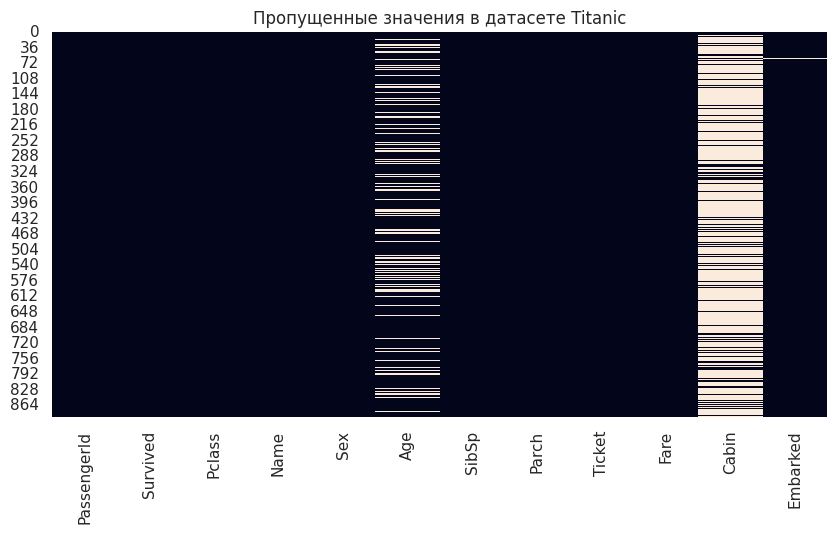

In [5]:

missing = df.isnull().sum()

print("Количество пропусков:")
print(missing)

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Пропущенные значения в датасете Titanic")
plt.show()


In [6]:

# Заполнение пропусков в возрасте медианой
df['Age'] = df['Age'].fillna(df['Age'].median())

# Заполнение пропусков в порте посадки
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Удаление Cabin из-за большого количества пропусков
df = df.drop(columns=['Cabin'])

# Проверка результата
print("Пропуски после обработки:")
print(df.isnull().sum())

print("\nРазмер обработанного датасета:", df.shape)


Пропуски после обработки:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

Размер обработанного датасета: (891, 11)


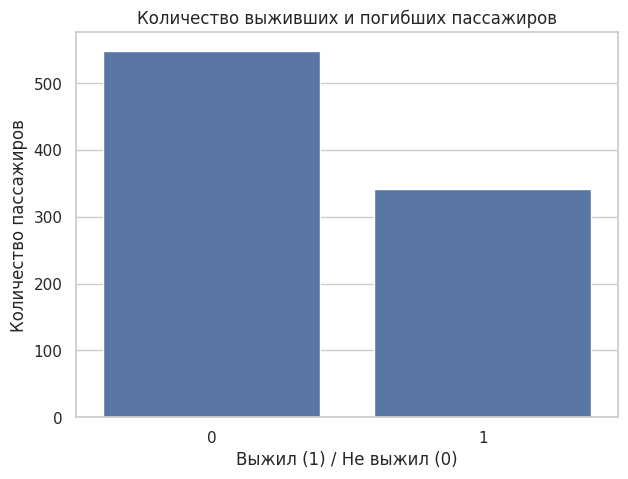

In [7]:

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Survived')
plt.title('Количество выживших и погибших пассажиров')
plt.xlabel('Выжил (1) / Не выжил (0)')
plt.ylabel('Количество пассажиров')
plt.show()


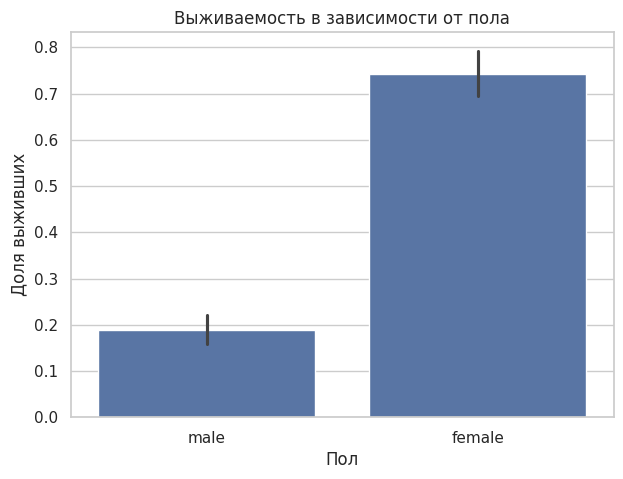

In [8]:

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='Sex', y='Survived')
plt.title('Выживаемость в зависимости от пола')
plt.xlabel('Пол')
plt.ylabel('Доля выживших')
plt.show()


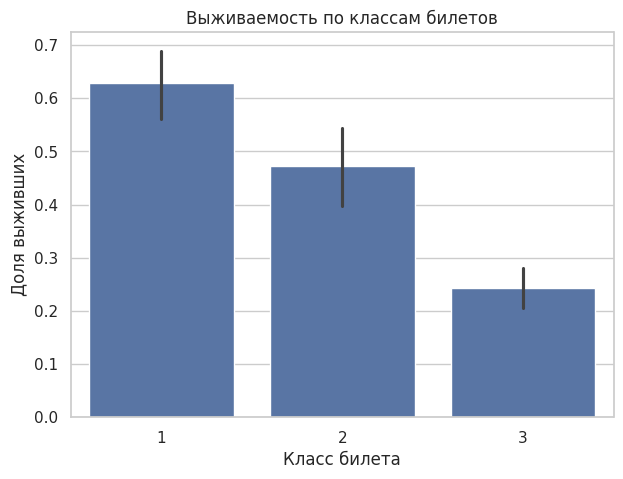

In [9]:

plt.figure(figsize=(7, 5))
sns.barplot(data=df, x='Pclass', y='Survived')
plt.title('Выживаемость по классам билетов')
plt.xlabel('Класс билета')
plt.ylabel('Доля выживших')
plt.show()


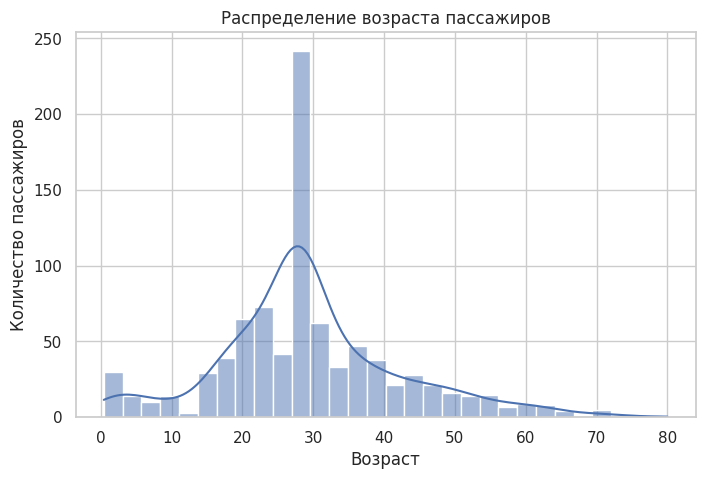

In [10]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', bins=30, kde=True)
plt.title('Распределение возраста пассажиров')
plt.xlabel('Возраст')
plt.ylabel('Количество пассажиров')
plt.show()


## Выводы по результатам анализа

В ходе лабораторной работы был проведён анализ набора данных Titanic.

В результате работы:
1. Загружен датасет Titanic, содержащий 891 запись и 12 столбцов.
2. Изучена структура данных и основные статистические характеристики.
3. Обнаружены пропущенные значения в столбцах Age, Cabin и Embarked.
4. Выполнена обработка пропусков: возраст заполнен медианой, порт посадки — наиболее частым значением, столбец Cabin удалён.
5. Построены графики распределения выживших пассажиров, выживаемости в зависимости от пола и класса, а также распределения возраста.

По графику возраста видно, что основная часть пассажиров находилась в возрастной группе от 20 до 35 лет.

Таким образом, были освоены основные методы первичного анализа, очистки и визуализации данных с использованием Python, Pandas, Matplotlib и Seaborn.